<a href="https://colab.research.google.com/github/Bhagawath18/dl-lab-/blob/main/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload and prepare the dataset

In [38]:

import os
import zipfile
import shutil
import glob
import subprocess
import sys
from google.colab import files
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "split-folders"
])
uploaded = files.upload()
zip_files = [f for f in uploaded if f.lower().endswith(".zip")]
if not zip_files:
    raise ValueError("Please upload a dataset ZIP file.")
extract_dir = "/content/road_dataset"
shutil.rmtree(extract_dir, ignore_errors=True)
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(zip_files[0], "r") as z:
    z.extractall(extract_dir)
image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
def has_images(folder):
    return any(
        f.lower().endswith(image_exts)
        for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    )
data_dir = None
for root, dirs, files_list in os.walk(extract_dir):
    class_dirs = [
        d for d in dirs
        if has_images(os.path.join(root, d))
    ]
    if len(class_dirs) >= 2:
        data_dir = root
        break
if data_dir is None:
    raise ValueError(
        "Could not find two class folders. "
        "Check your ZIP folder structure."
    )
class_names = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
    and has_images(os.path.join(data_dir, d))
])
print("Dataset path:", data_dir)
print("Classes:", class_names)
for cls in class_names:
    count = sum(
        f.lower().endswith(image_exts)
        for f in os.listdir(os.path.join(data_dir, cls))
        if os.path.isfile(os.path.join(data_dir, cls, f))
    )
    print(f"{cls}: {count} images")


Saving archive (1).zip to archive (1) (3).zip
Dataset path: /content/road_dataset/Road Classification
Classes: ['Broken', 'Not Broken']
Broken: 110 images
Not Broken: 94 images


Split the dataset


In [39]:

import splitfolders

output_dir = "/content/road_splits"
shutil.rmtree(output_dir, ignore_errors=True)

splitfolders.ratio(
    data_dir,
    output=output_dir,
    seed=42,
    ratio=(0.70, 0.15, 0.15),
    group_prefix=None
)

print("Dataset split completed.")
print("Training:", output_dir + "/train")
print("Validation:", output_dir + "/val")
print("Testing:", output_dir + "/test")


Copying files: 204 files [00:00, 2096.84 files/s]

Dataset split completed.
Training: /content/road_splits/train
Validation: /content/road_splits/val
Testing: /content/road_splits/test


Found 142 files belonging to 2 classes.
Found 30 files belonging to 2 classes.
Found 32 files belonging to 2 classes.
Class order: ['Broken', 'Not Broken']


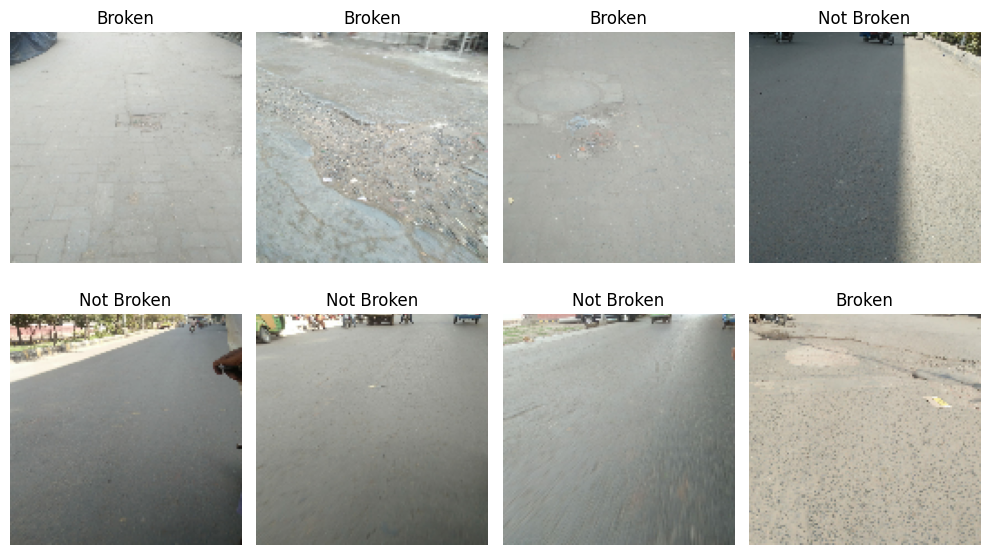

In [40]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Standardizing configurations for transfer learning
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

# Re-loading datasets using keras utility
train_ds = tf.keras.utils.image_dataset_from_directory(
    output_dir + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    output_dir + "/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    output_dir + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Class order:", class_names)

# Configure performance Prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Display sample dataset images
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy().item())])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [41]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Create a preprocessing layer specific to MobileNetV2 inputs
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Base pre-trained model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pre-trained weights
base_model.trainable = False

# Define our model architecture with transfer learning
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Augmentation layers
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),

    # Preprocessing layer scales inputs from [0, 255] to [-1, 1]
    layers.Lambda(preprocess_input),

    # Feature extractor base
    base_model,

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_5 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_5               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [42]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/best_road_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# Train the transfer learning model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 14s 823ms/step - accuracy: 0.5563 - loss: 0.8505 - val_accuracy: 0.7667 - val_loss: 0.4156
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 884ms/step - accuracy: 0.8521 - loss: 0.3335 - val_accuracy: 0.8667 - val_loss: 0.3130
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 764ms/step - accuracy: 0.8380 - loss: 0.3158 - val_accuracy: 0.9333 - val_loss: 0.2926
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 785ms/step - accuracy: 0.8732 - loss: 0.2898 - val_accuracy: 0.8667 - val_loss: 0.2900
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 878ms/step - accuracy: 0.8592 - loss: 0.2966 - val_accuracy: 0.9333 - val_loss: 0.2446
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 632ms/step - accuracy: 0.8873 - loss: 0.2597 - val_accuracy: 0.9000 - val_loss: 0.2500
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 801ms/step - accuracy: 0.9085 - loss: 0.2449 - val_accuracy: 0.8667 - val_loss: 0.2764
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 617ms/step - accuracy: 0.9366 - loss: 0.1622 - val_accuracy: 0.9000 - val_los

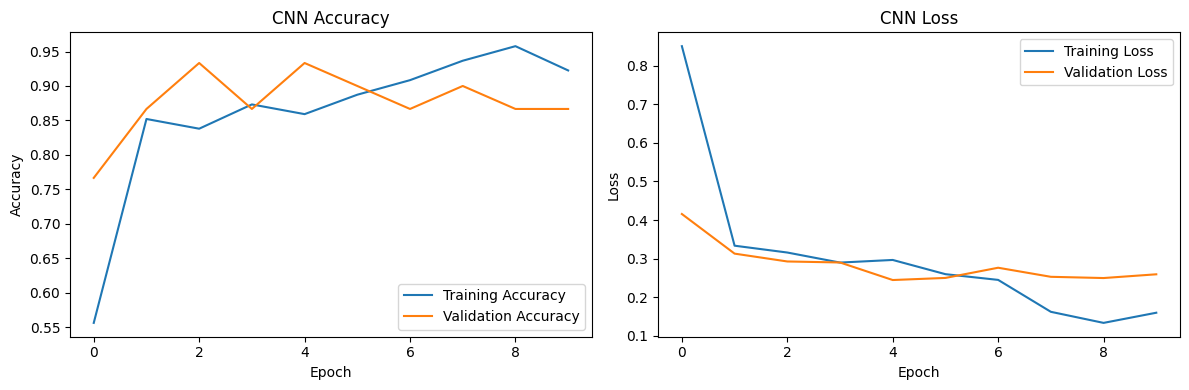

In [43]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()


Test Loss: 0.5412
Test Accuracy: 65.62%

Classification Report:
              precision    recall  f1-score   support

      Broken       0.75      0.53      0.62        17
  Not Broken       0.60      0.80      0.69        15

    accuracy                           0.66        32
   macro avg       0.68      0.66      0.65        32
weighted avg       0.68      0.66      0.65        32



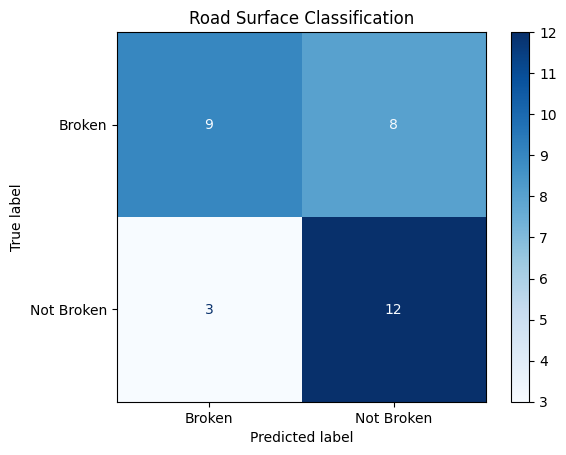

In [44]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

y_true = np.concatenate([
    labels.numpy().ravel().astype(int)
    for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues", values_format="d")

plt.title("Road Surface Classification")
plt.show()


Please upload a single image file (JPG, PNG, etc.) to test the model prediction:


Saving not_broken_83.jpg to not_broken_83 (1).jpg


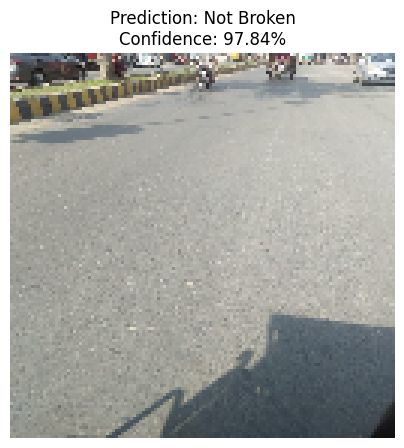

Predicted class: Not Broken
Model confidence: 97.84%


In [45]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import os

print("Please upload a single image file (JPG, PNG, etc.) to test the model prediction:")
uploaded_image = files.upload()

if uploaded_image:
    image_path = next(iter(uploaded_image))
    _, ext = os.path.splitext(image_path.lower())

    # Check if the uploaded file is a zip instead of an image
    if ext == '.zip':
        print(f"\n[Error] You uploaded a ZIP file ('{image_path}') instead of an image. Please run this cell again and select an image file (e.g. .jpg, .png).")
    else:
        try:
            img = load_img(image_path, target_size=IMG_SIZE)
            img_array = img_to_array(img)
            img_array = np.expand_dims(img_array, axis=0)

            probability = float(model.predict(img_array, verbose=0)[0][0])
            predicted_index = 1 if probability >= 0.5 else 0
            confidence = probability if predicted_index == 1 else 1 - probability

            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.axis("off")
            plt.title(
                f"Prediction: {class_names[predicted_index]}\n"
                f"Confidence: {confidence * 100:.2f}%"
            )
            plt.show()

            print("Predicted class:", class_names[predicted_index])
            print(f"Model confidence: {confidence * 100:.2f}%")
        except Exception as e:
            print(f"An error occurred while loading the image: {e}")
else:
    print("No file uploaded.")

In [46]:

model.save("/content/road_surface_cnn.keras")

print("Model saved successfully.")

files.download("/content/road_surface_cnn.keras")


Model saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>